<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Chart Rendering](https://github.com/Query-farm/vgi-chart)

Render query results as line, bar, pie, scatter, and histogram PNG charts with JFreeChart.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-chart/blob/main/notebooks/02_observations_and_contributions.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-chart/blob/main/notebooks/README.md)


## 02 · What does one plotted observation represent?

**Does a high weekly failure percentage identify the largest contributor to total failures?** The same twelve synthetic region-week observations support three different views: volume versus rate, the distribution of weekly rates, and each region's share of all failures. Their units and denominators differ.

The first notebook changes a reporting horizon. Here all four weeks stay fixed: 7,800 requests and 370 failures. This is an illustrative complete population, not a sample used for inference. There is no causal claim about request volume.

### Choose a histogram resolution

`HIST_BINS` is an integer **2–8**, default **4**, experiment **8**. It changes only the number of equal-width bins spanning the observed minimum and maximum weekly rate. Raw observations, scatter coordinates and failure shares remain fixed. More bins can expose gaps without adding information.

In [1]:
HIST_BINS = 4

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.25":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.25"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
if type(HIST_BINS) is not int or not 2 <= HIST_BINS <= 8:
    raise ValueError("HIST_BINS must be an integer from 2 to 8.")
from vgi_notebooks import connect, prepare
from vgi_notebooks.presentation import prose
from IPython.display import display

prepare("chart")
from chart_example import show_worker_png  # noqa: E402

session = connect(globals())
SOURCE = (
    "Source: 12 synthetic region-week counts · vgi-chart v0.4.0 · JFreeChart 1.5.6 / Java 21.0.8"
)

### Attach the released chart renderer

The short literal launcher uses published **v0.4.0**, checks its immutable JAR digest and runs managed **Java 21.0.8** from a separate locked environment. It never uses system Java or compiles source. First use downloads Python, the shared package, VGI, Java and the JAR; rendering thereafter is local CPU work. The shared connection uses an empty temporary secret directory and disables persistent secrets.

This worker returns **PNG**, not SVG. Folded presentation code validates the PNG signature/dimensions and embeds the **unchanged worker bytes** in an SVG frame containing explanation and provenance. The analytical marks remain raster content. The notebook does not redraw them in Python. Raw PNGs are saved under ignored `artifacts/worker-png/` and the published SVG links retain their embedded PNGs.

These small inputs fit one Arrow batch. The renderer can emit a chart-so-far for each batch on larger inputs; we require one complete image, rather than silently selecting the last result. An empty input emits zero image rows.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'chart' (TYPE vgi,
    LOCATION 'uv run --locked --no-project --python 3.13 chart_release.py v0.4.0');

,Success


### Keep the row grain explicit

Each row is one region-week. Its request count is a volume and its failure percentage is `100 × failures / requests`. A scatter point and a histogram observation each represent one row, regardless of request volume. All counts are invented, with positive denominators and failures bounded by requests.

In [5]:
%%sql
CREATE TABLE observations AS
SELECT * FROM (VALUES
    (1, 'Aster', 1000, 20), (2, 'Aster', 1200, 36),
    (3, 'Aster', 800, 64),  (4, 'Aster', 1400, 112),
    (1, 'Briar', 100, 10),  (2, 'Briar', 100, 10),
    (3, 'Briar', 500, 15),  (4, 'Briar', 500, 15),
    (1, 'Cedar', 400, 16),  (2, 'Cedar', 500, 20),
    (3, 'Cedar', 600, 24),  (4, 'Cedar', 700, 28)
) AS t(week, region, requests, failures);

CREATE TABLE weekly AS
SELECT *, 100.0 * failures / requests AS failure_pct
FROM observations WHERE week BETWEEN 1 AND 4;

SELECT week, region, requests, failures, failure_pct
FROM weekly ORDER BY region, week;

,week,region,requests,failures,failure_pct
0,1,Aster,1000,20,2.0
1,2,Aster,1200,36,3.0
2,3,Aster,800,64,8.0
3,4,Aster,1400,112,8.0
4,1,Briar,100,10,10.0
5,2,Briar,100,10,10.0
6,3,Briar,500,15,3.0
7,4,Briar,500,15,3.0
8,1,Cedar,400,16,4.0
9,2,Cedar,500,20,4.0


### Compare volume and rate without treating overlap as absence

A numeric scatter axis preserves the difference between 100 and 1,400 requests. The repeated Briar coordinates are intentional: two weeks at (100, 10%) and two at (500, 3%) overlap. The SQL multiplicity table makes those hidden observations visible. Cedar's four rates are equal, but its request volumes differ.

In [6]:
%%sql multiplicities <<
SELECT region,requests,failure_pct,count(*) AS region_week_rows
FROM weekly GROUP BY ALL ORDER BY region,requests;


In [7]:
display(multiplicities)
prose(
    f"The **{int(multiplicities.region_week_rows.sum())} region-week rows** occupy **{len(multiplicities)} distinct region/coordinate combinations**. Briar's coincident points are repeated observations, not deduplication. Its 10% weeks each have only 100 requests."
)

,region,requests,failure_pct,region_week_rows
0,Aster,800,8.0,1
1,Aster,1000,2.0,1
2,Aster,1200,3.0,1
3,Aster,1400,8.0,1
4,Briar,100,10.0,2
5,Briar,500,3.0,2
6,Cedar,400,4.0,1
7,Cedar,500,4.0,1
8,Cedar,600,4.0,1
9,Cedar,700,4.0,1


The **12 region-week rows** occupy **10 distinct region/coordinate combinations**. Briar's coincident points are repeated observations, not deduplication. Its 10% weeks each have only 100 requests.

In [8]:
%%sql
CREATE TABLE scatter_png AS SELECT png FROM chart.main.chart_scatter(
 (SELECT requests AS "Requests per region-week",failure_pct AS "Failure rate (%)",region AS "Region"
  FROM weekly ORDER BY region,week),
 x:='Requests per region-week',y:='Failure rate (%)',series:='Region',
 title:='Volume versus weekly failure rate',width:=1100,height:=640);


,Count


In [9]:
%%sql scatter_blob <<
SELECT png FROM scatter_png;

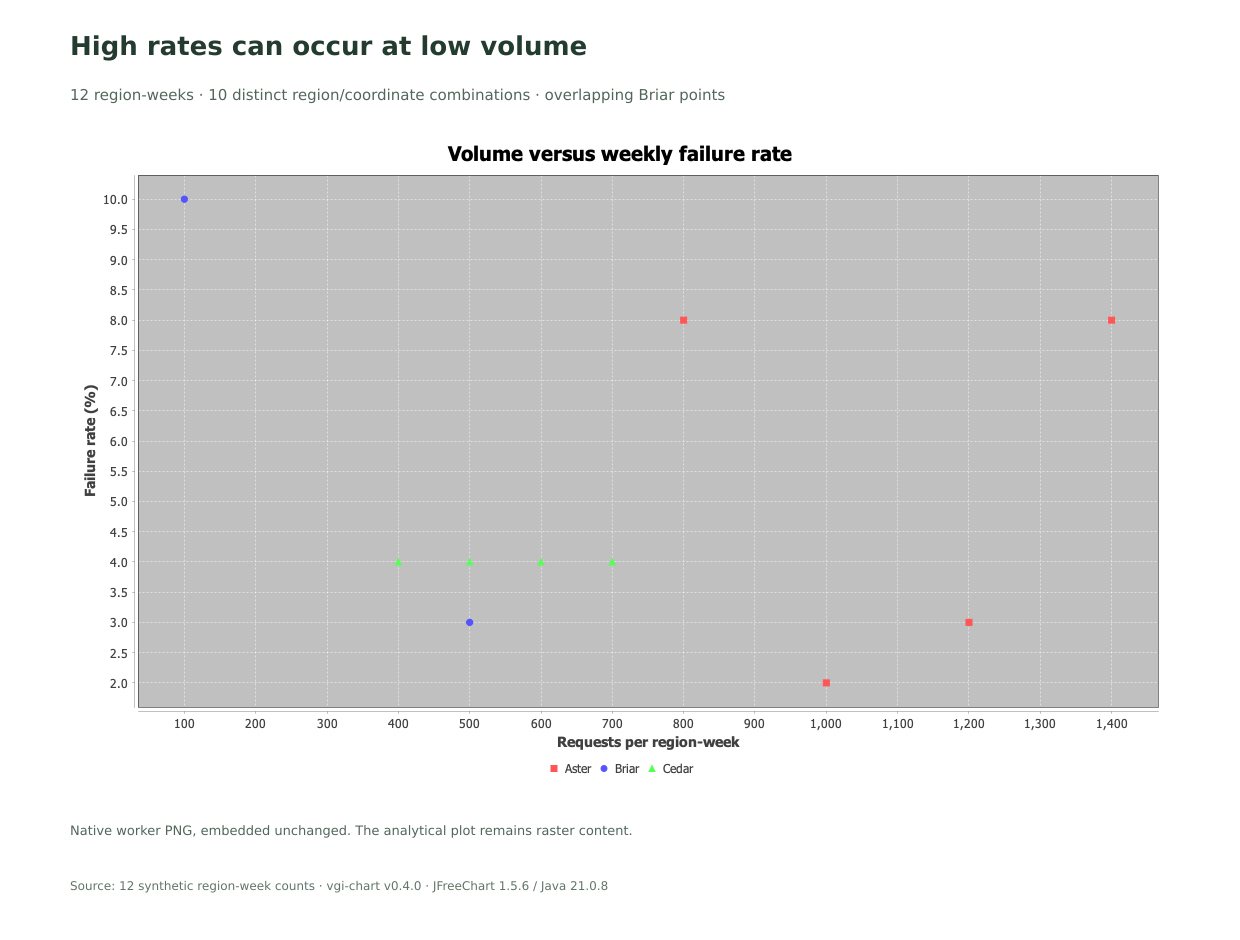

{'png_rows': 1,
 'png_bytes': 40624,
 'width_px': 1100,
 'height_px': 640,
 'worker_png_sha256': 'b9c216d29a685539dec96f85a4953c65d32cbae3f98ae48668b6f5b0ad8ab5b9',
 'embedded_bytes_unchanged': True,
 'native_format': 'PNG',
 'presentation_format': 'SVG with raster image'}

In [10]:
scatter_details = show_worker_png(
    scatter_blob,
    "volume-rate",
    "High rates can occur at low volume",
    "12 region-weeks · 10 distinct region/coordinate combinations · overlapping Briar points",
    SOURCE,
)
display(scatter_details)

### Count rows in rate intervals

`chart_histogram` gives each of the twelve rows one vote. It does **not** replicate observations by request count. We independently audit the equal-width intervals in SQL: left-inclusive/right-exclusive, with the maximum included in the final bin. Empty intervals remain explicit. Edges are in percentage points of failure rate; the vertical quantity is a count of region-week rows.

The native histogram uses the label `frequency`; in this story that means the number of region-week observations, not requests or failures. If the input population changed, the worker's automatic minimum/maximum could also change the bin edges. Our experiment holds that population fixed.

In [11]:
%%sql bins <<
CREATE TABLE rate_bounds AS SELECT min(failure_pct) AS lo,max(failure_pct) AS hi FROM weekly;
CREATE TABLE binned_rows AS SELECT w.*,least({{ HIST_BINS }}-1,
 floor((failure_pct-lo)/(hi-lo)*{{ HIST_BINS }}))::INTEGER AS bin_id
FROM weekly w CROSS JOIN rate_bounds;
CREATE TABLE bin_audit AS
SELECT i AS bin_id,lo+i*(hi-lo)/{{ HIST_BINS }} AS lower_pct,
 lo+(i+1)*(hi-lo)/{{ HIST_BINS }} AS upper_pct,i={{ HIST_BINS }}-1 AS upper_inclusive,
 (SELECT count(*) FROM binned_rows b WHERE b.bin_id=i) AS region_week_rows
FROM range({{ HIST_BINS }}) t(i) CROSS JOIN rate_bounds;
SELECT * FROM bin_audit ORDER BY bin_id;

In [12]:
display(bins)
prose(
    f"The selected **{HIST_BINS} bins** account for all **{int(bins.region_week_rows.sum())} rows**, including **{int((bins.region_week_rows == 0).sum())} empty intervals**. Increasing resolution changes the visible gaps, not the underlying observations."
)

,bin_id,lower_pct,upper_pct,upper_inclusive,region_week_rows
0,0,2.0,4.0,False,4
1,1,4.0,6.0,False,4
2,2,6.0,8.0,False,0
3,3,8.0,10.0,True,4


The selected **4 bins** account for all **12 rows**, including **1 empty intervals**. Increasing resolution changes the visible gaps, not the underlying observations.

In [13]:
%%sql
CREATE TABLE histogram_png AS SELECT png FROM chart.main.chart_histogram(
 (SELECT failure_pct AS "Weekly failure rate (%)" FROM weekly ORDER BY region,week),
 value:='Weekly failure rate (%)',bins:={{ HIST_BINS }},
 title:='Equal-weight region-week distribution',width:=1100,height:=640);

,Count


In [14]:
%%sql histogram_blob <<
SELECT png FROM histogram_png;

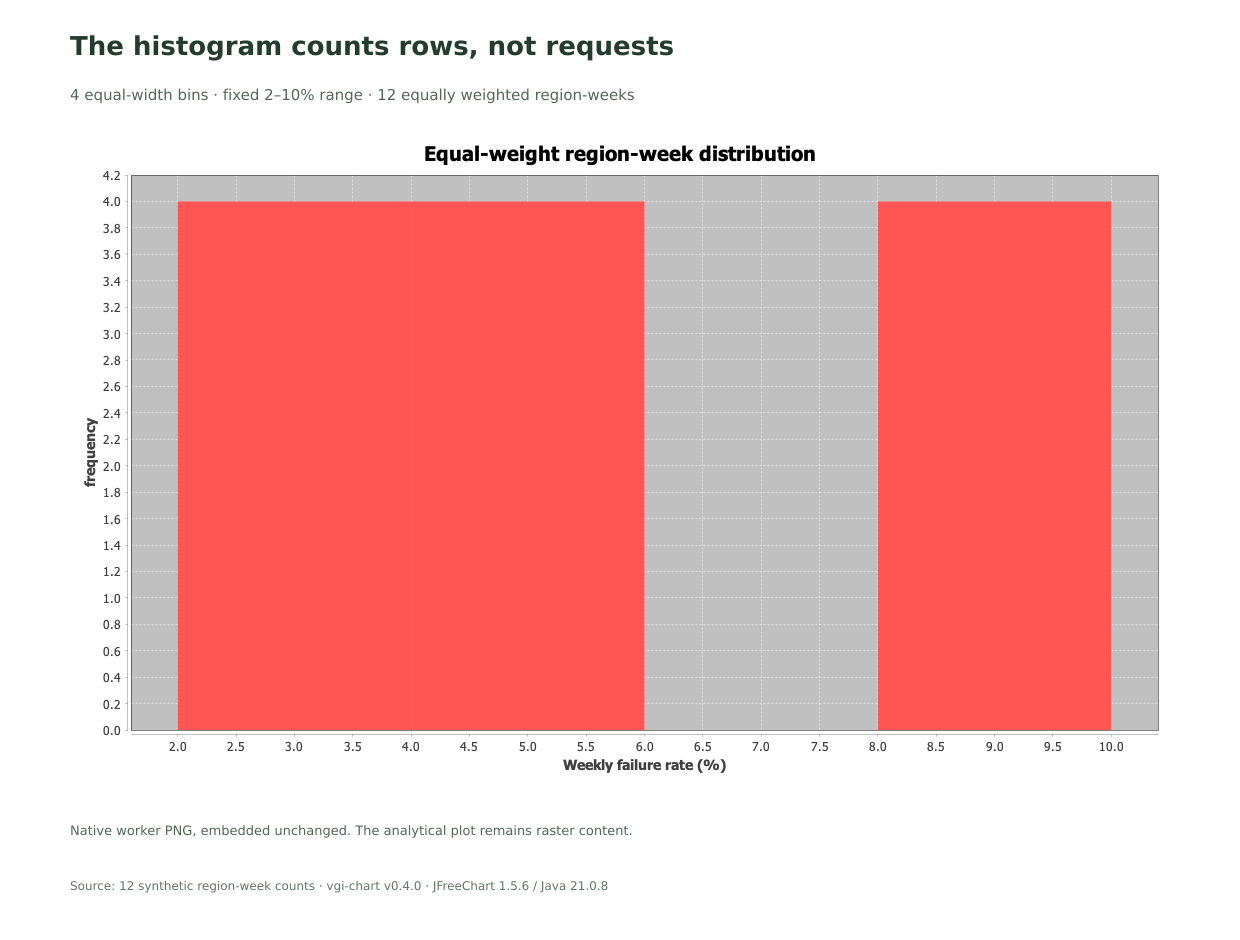

{'png_rows': 1,
 'png_bytes': 36565,
 'width_px': 1100,
 'height_px': 640,
 'worker_png_sha256': 'ab08ced312c98621090b624048e1a1d83e811e218428a79aebb938ed42316789',
 'embedded_bytes_unchanged': True,
 'native_format': 'PNG',
 'presentation_format': 'SVG with raster image'}

In [15]:
histogram_details = show_worker_png(
    histogram_blob,
    f"rate-distribution-{HIST_BINS}",
    "The histogram counts rows, not requests",
    f"{HIST_BINS} equal-width bins · fixed 2–10% range · 12 equally weighted region-weeks",
    SOURCE,
)
display(histogram_details)

### Allocate a total using counts, not rates

A pie requires additive parts of a common total. We aggregate **failure counts**, not percentages. Each region's slice is its share of 370 failures across all weeks. Aster can dominate this total despite Briar having the highest mean weekly rate: the amount of traffic also matters. The labels show counts; the table shows exact shares and within-region rates to prevent confusing the denominators.

In [16]:
%%sql shares <<
CREATE TABLE failure_shares AS
SELECT region,sum(requests) AS requests,sum(failures) AS failures,
 100.0*sum(failures)/sum(sum(failures)) OVER() AS share_of_all_failures_pct,
 100.0*sum(failures)/sum(requests) AS within_region_rate_pct
FROM weekly GROUP BY region;
SELECT * FROM failure_shares ORDER BY region;

In [17]:
display(shares)
largest = shares.loc[shares.failures.idxmax()]
prose(
    f"**{largest.region}** contributes **{int(largest.failures)} of {int(shares.failures.sum())} failures ({largest.share_of_all_failures_pct:.1f}%)**. Its within-region failure rate is **{largest.within_region_rate_pct:.2f}%**. These two percentages have different denominators."
)

,region,requests,failures,share_of_all_failures_pct,within_region_rate_pct
0,Aster,4400.0,232.0,62.702703,5.272727
1,Briar,1200.0,50.0,13.513514,4.166667
2,Cedar,2200.0,88.0,23.783784,4.000000


**Aster** contributes **232 of 370 failures (62.7%)**. Its within-region failure rate is **5.27%**. These two percentages have different denominators.

In [18]:
%%sql
CREATE TABLE pie_png AS SELECT png FROM chart.main.chart_pie(
 (SELECT region || ' — ' || failures || ' failures' AS "Region and failure count",failures AS "Failures"
  FROM failure_shares ORDER BY region),label:='Region and failure count',value:='Failures',
 title:='Share of all 370 failures',width:=1100,height:=640);

,Count


In [19]:
%%sql pie_blob <<
SELECT png FROM pie_png;

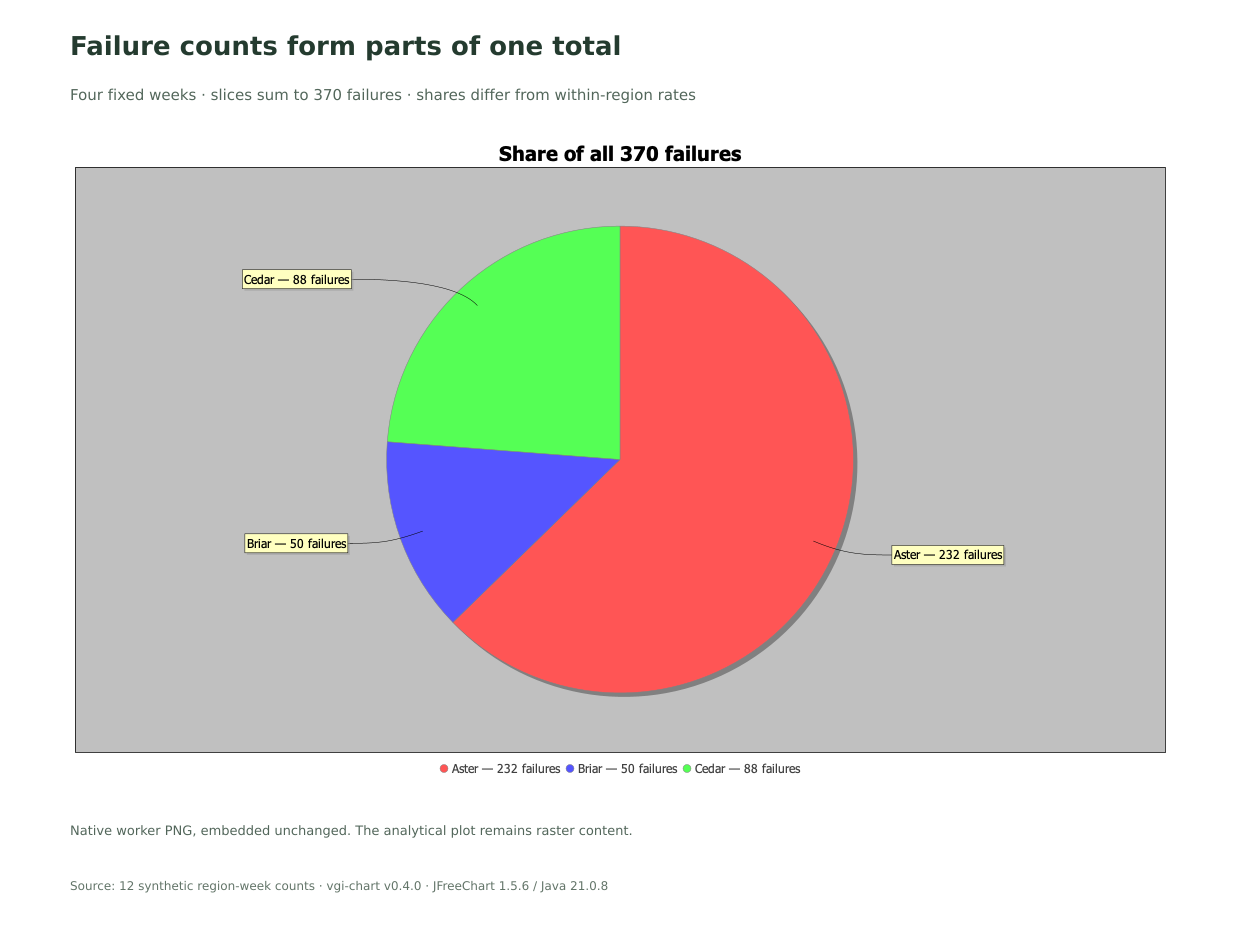

{'png_rows': 1,
 'png_bytes': 35259,
 'width_px': 1100,
 'height_px': 640,
 'worker_png_sha256': '9892ac04a3def95651a390835c68a5611230c04245a997e9429960263b1221f9',
 'embedded_bytes_unchanged': True,
 'native_format': 'PNG',
 'presentation_format': 'SVG with raster image'}

In [20]:
pie_details = show_worker_png(
    pie_blob,
    "failure-contributions",
    "Failure counts form parts of one total",
    "Four fixed weeks · slices sum to 370 failures · shares differ from within-region rates",
    SOURCE,
)
display(pie_details)

### Reconcile the data and image boundaries

The renderer calls were materialized before DataFrame capture, so presentation does not execute them twice. Verify each image and the underlying sums. The final empty-input query demonstrates the worker's zero-row result; it must not be mistaken for a successfully rendered blank chart.

In [21]:
%%sql checks <<
SELECT 'fixed row grain and population' AS check_name,
 count(*)=12 AND count(DISTINCT (region,week))=12 AND sum(requests)=7800 AND sum(failures)=370 AS passed FROM weekly
UNION ALL SELECT 'positive denominators and bounded counts',bool_and(requests>0 AND failures BETWEEN 0 AND requests) FROM weekly
UNION ALL SELECT 'bin counts conserve observations',sum(region_week_rows)=12 AND count(*)={{ HIST_BINS }} FROM bin_audit
UNION ALL SELECT 'fixed observed range',lo=2 AND hi=10 FROM rate_bounds
UNION ALL SELECT 'failure shares reconcile',abs(sum(share_of_all_failures_pct)-100)<1e-9 AND sum(failures)=370 FROM failure_shares
UNION ALL SELECT 'one scatter PNG',count(*)=1 AND bool_and(png[1:4]='\x89PNG'::BLOB) FROM scatter_png
UNION ALL SELECT 'one histogram PNG',count(*)=1 AND bool_and(png[1:4]='\x89PNG'::BLOB) FROM histogram_png
UNION ALL SELECT 'one pie PNG',count(*)=1 AND bool_and(png[1:4]='\x89PNG'::BLOB) FROM pie_png
UNION ALL SELECT 'empty relation produces no image',count(*)=0 FROM chart.main.chart_line(
 (SELECT week AS x,failure_pct AS y FROM weekly WHERE false),x:='x',y:='y');

In [22]:
display(checks)
assert checks.passed.fillna(False).all(), "A population, bin, share or PNG invariant failed."

,check_name,passed
0,fixed row grain and population,True
1,positive denominators and bounded counts,True
2,bin counts conserve observations,True
3,fixed observed range,True
4,failure shares reconcile,True
5,one scatter PNG,True
6,one histogram PNG,True
7,one pie PNG,True
8,empty relation produces no image,True


### Experiment: refine the bins, preserve the population

Predict the effect of changing **`HIST_BINS` from 4 to 8**. The fixed 2–10% span gives two-percentage-point intervals at four bins and one-point intervals at eight. Compare the empty intervals and counts with the histogram. The scatter, failure shares, 7,800 requests and 370 failures must remain identical.

Use the separate output directory in the README. The displayed histogram changes its resolution; it does not establish a new cluster or a causal relationship. A row-count distribution and a total-failure composition answer different questions even when drawn from the same table.

In [23]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-chart](https://github.com/Query-farm/vgi-chart)
